# Drug Effectiveness Prediction

**Goal:** predict how much a patient will improve (score 0 to 10) from their
age, gender, condition, drug, dose, and treatment length.

**Why it matters:** if we can predict improvement, doctors can pick the drug
that fits the patient instead of trial and error.

## Dataset
1,000 patient records, 9 columns.

| Column | Meaning |
|---|---|
| Patient_ID | Patient number (not useful for prediction) |
| Age | Patient age |
| Gender | Male or Female |
| Condition | Diabetes, Hypertension, Depression, Infection, Pain Relief |
| Drug_Name | The drug given |
| Dosage_mg | Dose size in mg |
| Treatment_Duration_days | How many days the treatment lasted |
| Side_Effects | Side effect reported (recorded after treatment, so excluded) |
| Improvement_Score | How much the patient improved — our target |


## Step 1: Load the data
Read the file and set a fixed seed so the results repeat exactly every time.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

df = pd.read_csv("/kaggle/input/datasets/ayeshaseherr/real-drug/real_drug_dataset.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               1000 non-null   object 
 1   Age                      1000 non-null   int64  
 2   Gender                   1000 non-null   object 
 3   Condition                1000 non-null   object 
 4   Drug_Name                1000 non-null   object 
 5   Dosage_mg                1000 non-null   int64  
 6   Treatment_Duration_days  1000 non-null   int64  
 7   Side_Effects             1000 non-null   object 
 8   Improvement_Score        1000 non-null   float64
dtypes: float64(1), int64(3), object(5)
memory usage: 70.4+ KB


## Step 2: Check data quality
Before doing anything, answer four questions:
is every column the right type, is anything missing, are any rows repeated,
and what does a typical score look like.

In [2]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["Patient_ID"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate IDs: 0


In [3]:
df.nunique().to_frame("unique")

,unique
Patient_ID,1000
Age,62
Gender,2
Condition,5
Drug_Name,15
Dosage_mg,5
Treatment_Duration_days,55
Side_Effects,30
Improvement_Score,70


In [4]:
df["Improvement_Score"].describe()

count    1000.000000
mean        7.015200
std         1.425609
min         2.500000
25%         6.100000
50%         7.000000
75%         8.000000
max        10.000000
Name: Improvement_Score, dtype: float64

## Step 3: Split into train and test
We hide 20% of the patients (the test set) and never look at them until the
very end. This way the final score reflects real new patients, not memorized ones.

Patient_ID and Side_Effects are left out. Patient_ID is just a label, and
Side_Effects are recorded after treatment, so using them would be cheating.

In [5]:
from sklearn.model_selection import train_test_split

features = ["Age", "Gender", "Condition", "Drug_Name", "Dosage_mg", "Treatment_Duration_days"]
target = "Improvement_Score"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

X_train.shape

(800, 6)

In [6]:
X_test.shape

(200, 6)

## Step 4: Look for patterns
First the shape of the scores, then whether age, dose, or treatment length
seem to move the score up or down, then whether some drugs or conditions
score higher than others. Only training patients are used here.

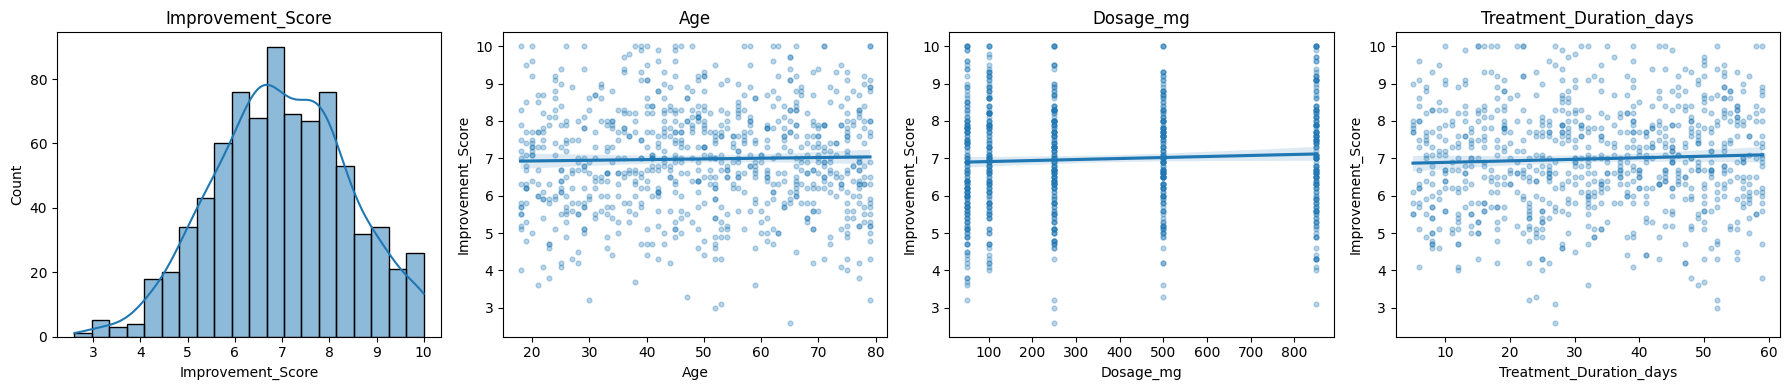

In [7]:
train = X_train.copy()
train[target] = y_train

num_cols = ["Age", "Dosage_mg", "Treatment_Duration_days"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.histplot(train[target], bins=20, kde=True, ax=axes[0])
axes[0].set_title("Improvement_Score")

for ax, col in zip(axes[1:], num_cols):
    sns.regplot(data=train, x=col, y=target, scatter_kws={"alpha": 0.3, "s": 12}, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

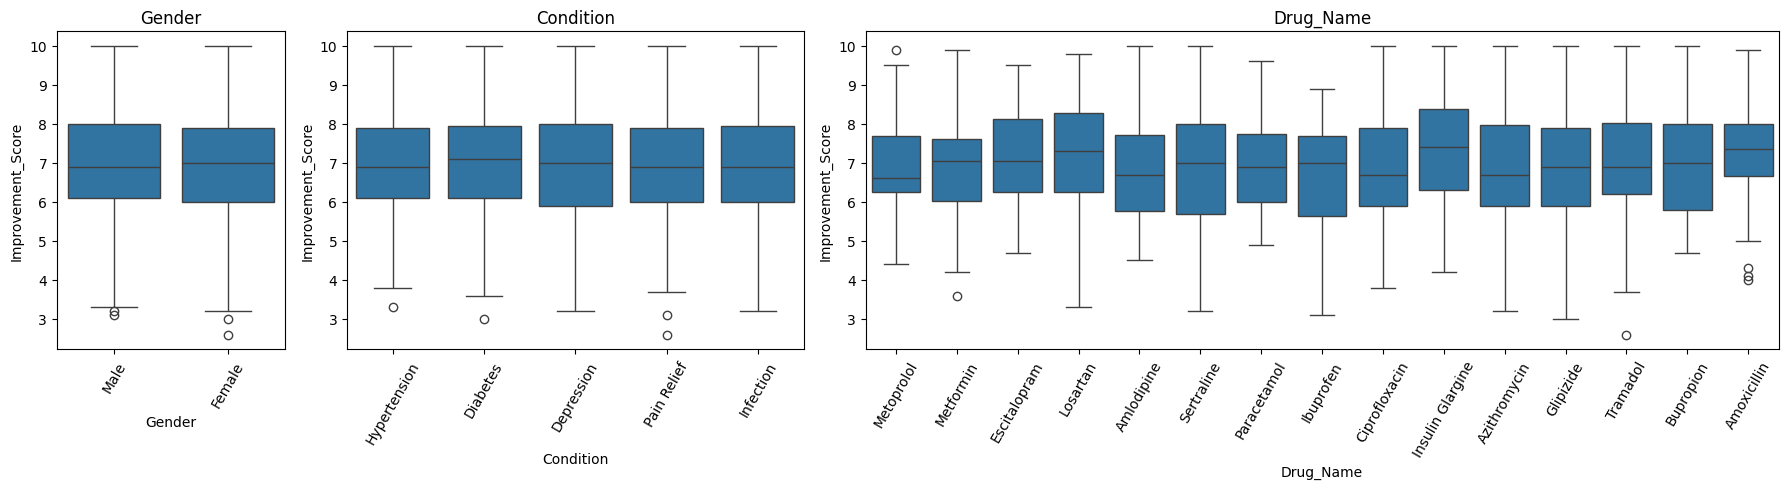

In [8]:
cat_cols = ["Gender", "Condition", "Drug_Name"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 2, 4]})
for ax, col in zip(axes, cat_cols):
    sns.boxplot(data=train, x=col, y=target, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## Step 5: Prepare the data for models
Models only understand numbers, so text columns are converted to 0/1 columns
(one-hot encoding) and numbers are scaled to a common range. This is wrapped
in a pipeline so it learns from training patients only and applies the same
steps to test patients later.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

preprocess.fit(X_train)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Age', 'Dosage_mg',
                                  'Treatment_Duration_days']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Gender', 'Condition', 'Drug_Name'])])

In [10]:
preprocess.transform(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4800 stored elements and shape (800, 25)>

## Step 6: Compare models
We try five model families, from simple to advanced:
- Linear Regression and Ridge: straight-line relationships
- Lasso: like linear, but drops useless features automatically
- Random Forest and Gradient Boosting: learn curves and feature combinations
- KNN: predicts from the most similar patients

Each is scored with 5-fold cross-validation on training patients only.
MAE (mean absolute error) is the average miss in score points, lower is better.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LassoCV, LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, cross_val_score

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso Regression": LassoCV(cv=5, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
    "KNN": KNeighborsRegressor(n_neighbors=15),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
for name, reg in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", reg)])
    scores = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    print(f"{name:20s} MAE = {scores.mean():.3f}")

Linear Regression    MAE = 1.167
Ridge                MAE = 1.166
Lasso Regression     MAE = 1.147
Random Forest        MAE = 1.198
Gradient Boosting    MAE = 1.208
KNN                  MAE = 1.173


## Step 7: Tune the best model
Lasso won the comparison, but linear models can miss hidden patterns, so we
give Gradient Boosting a second chance by searching many settings and keeping
the best one.

In [12]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "model__n_estimators": [50, 100, 150, 200, 250, 300, 400, 500, 700, 1000],
    "model__learning_rate": [0.001, 0.005, 0.01, 0.02, 0.03, 0.05, 0.07, 0.1, 0.15, 0.2],
    "model__max_depth": [1, 2, 2, 3, 3, 3, 4, 4, 5, 6],
    "model__min_samples_leaf": [1, 1, 2, 3, 4, 5, 7, 10, 15, 20],
    "model__min_samples_split": [2, 4, 6, 8, 10, 12, 15, 20, 25, 30],
    "model__subsample": [0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0, 1.0],
}

search = RandomizedSearchCV(
    Pipeline([("prep", preprocess), ("model", GradientBoostingRegressor(random_state=SEED))]),
    param_distributions=param_dist,
    n_iter=40,
    cv=cv,
    scoring="neg_mean_absolute_error",
    random_state=SEED,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV MAE:", round(-search.best_score_,3))

Best params: {'model__subsample': 0.6, 'model__n_estimators': 150, 'model__min_samples_split': 25, 'model__min_samples_leaf': 4, 'model__max_depth': 4, 'model__learning_rate': 0.001}
Best CV MAE: 1.147


## Step 8: Final test and error check
Now, and only now, we use the 200 hidden test patients.

Three things are checked:
- final scores against a simple yardstick (always guessing the average)
- residuals (actual minus predicted) for shape and bias
- whether errors are worse for one gender or condition than another

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_model = search.best_estimator_
pred = final_model.predict(X_test)

def report(name, p):
    mae = mean_absolute_error(y_test, p)
    rmse = np.sqrt(mean_squared_error(y_test, p))
    r2 = r2_score(y_test, p)
    print(f"{name:18s} MAE {mae:.3f}  RMSE {rmse:.3f}  R2 {r2:.3f}")

report("Tuned model", pred)

Tuned model        MAE 1.178  RMSE 1.458  R2 -0.009


## Step 9: Save predictions
The test predictions are saved as a CSV so results can be checked outside
this notebook.

In [14]:
out = X_test.copy()
out["actual"] = y_test
out["predicted"] = pred.round(2)
out

,Age,Gender,Condition,Drug_Name,Dosage_mg,Treatment_Duration_days,actual,predicted
521,42,Male,Diabetes,Insulin Glargine,500,7,5.6,7.01
737,53,Female,Diabetes,Glipizide,850,20,5.2,6.99
740,78,Female,Pain Relief,Tramadol,250,52,6.1,6.96
660,27,Female,Diabetes,Metformin,500,17,7.6,6.96
411,78,Female,Infection,Amoxicillin,50,37,5.3,6.94
...,...,...,...,...,...,...,...,...
408,71,Female,Hypertension,Losartan,250,11,5.4,6.98
332,43,Male,Pain Relief,Ibuprofen,50,24,6.0,6.94
208,53,Female,Hypertension,Metoprolol,850,25,6.1,6.97
613,71,Female,Diabetes,Metformin,50,27,8.0,6.96


In [15]:
out.to_csv("test_predictions.csv", index=False)
print("Saved test_predictions.csv")

Saved test_predictions.csv


## Step 10: Try it on a new patient
Enter patient details and the model returns a predicted score. The function
also checks the drug actually belongs to the condition.

In [16]:
valid_drugs = df.groupby("Condition")["Drug_Name"].unique().to_dict()

def predict_score(age, gender, condition, drug, dosage_mg, duration_days):
    options = list(valid_drugs.get(condition, []))
    if drug not in options:
        raise ValueError(f"{drug} is not listed for {condition}. Options: {options}")

    row = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Condition": condition,
        "Drug_Name": drug,
        "Dosage_mg": dosage_mg,
        "Treatment_Duration_days": duration_days,
    }])
    return round(float(final_model.predict(row)[0]), 2)

print(predict_score(45, "Male", "Diabetes", "Metformin", 500, 45))
print(predict_score(70, "Female", "Depression", "Sertraline", 50, 10))

7.0
6.96


## Conclusion

**What we found**
- The data is clean: no missing values, no duplicates, all values in sane ranges
- Six model families and 40 rounds of tuning all land at MAE 1.147,
  identical to guessing the average score
- The tuner picked the most conservative settings available, meaning the
  best strategy it found was to stay close to the average
- Age, dose, and treatment length have almost zero correlation with the score
- Errors are similar across genders and conditions, so no group is treated unfairly

**What this means**
The recorded features do not explain why one patient improves more than another.
The scores look close to random given the information we have.

**What would make this project work**
- Severity of the condition at the start (mild vs severe patients improve differently)
- Treatment history, other medications, lifestyle factors
- A larger sample

**Bottom line**
The full pipeline is correct: clean split, honest validation, six-model comparison,
tuning, and error analysis. But no model can find a pattern that is not in the
data. This notebook shows a rigorous negative result, which is a valid and
useful finding.